In [ ]:
import numpy as np
import scipy as sp
from pyscf import gto, scf
import perceval as pcvl
from qiskit.quantum_info import Pauli, PauliList, Statevector, SparsePauliOp, Operator
from qlass.vqe.ansatz import list_of_ones
from qiskit.circuit.library import n_local
from perceval.algorithm import Sampler
from qiskit import QuantumCircuit, transpile
from perceval.converters import QiskitConverter
from perceval.components import catalog
from perceval.simulators import Simulator
from perceval import BasicState
import warnings
warnings.filterwarnings('ignore')

/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


In [2]:
'''decompose operator to pauli'''
pauli_matrices = {
    'I': np.array([[1, 0], [0, 1]]),
    'X': np.array([[0, 1], [1, 0]]),
    'Y': np.array([[0, -1j], [1j, 0]]),
    'Z': np.array([[1, 0], [0, -1]]),
}

# Generate all tensor products of Pauli matrices for n qubits
def generate_pauli_strings(n):
    from itertools import product
    labels = ['I', 'X', 'Y', 'Z']
    pauli_strings = [''.join(p) for p in product(labels, repeat=n)]
    return pauli_strings


# Create a dictionary to map Pauli labels to their ndarray representations
def create_pauli_to_matrix(n):
    pauli_strings = generate_pauli_strings(n)
    pauli_to_matrix = {}
    for label in pauli_strings:
        matrix = pauli_matrices[label[0]]
        for char in label[1:]:
            matrix = np.kron(matrix, pauli_matrices[char])
        pauli_to_matrix[label] = matrix
    return pauli_to_matrix


# Function to decompose an operator into Pauli strings
def decompose_operator_to_pauli_list(operator):
    nqubits = int(np.log2(operator.dim[0]))  # Number of qubits
    pauli_to_matrix = create_pauli_to_matrix(nqubits)
    pauli_list = {}
    dim = operator.dim[0]

    # Iterate over all possible Pauli matrices
    for pauli_str, pauli_matrix in pauli_to_matrix.items():
        coeff = np.trace(np.dot(operator.data, pauli_matrix)) / dim

        # Check if coefficient is non-zero
        if np.abs(coeff) > 1e-10:
            pauli_list[pauli_str] = pauli_list.get(pauli_str, 0) + coeff

    # Convert to a list of tuples (Pauli object, coefficient)
    pauli_list = [(Pauli(pauli_str), coeff) for pauli_str, coeff in pauli_list.items()]
    return pauli_list

P = [Pauli('X'), Pauli('Y'), Pauli('Z'), Pauli('I')]
X, Y, Z, I = Operator(P[0]).data, Operator(P[1]).data, Operator(P[2]).data, Operator(P[3]).data

def list_Pauli_to_SparsePauliOp(list_pauli: list):

    pauli_list: list[Pauli] = []
    pauli_coeff: list[float] = []
    for lines in list_pauli:
        pauli_list.append(lines[0])
        pauli_coeff.append(lines[1])
    return SparsePauliOp(pauli_list, coeffs=pauli_coeff)


def transformation_Hmatrix_Hqubit(Hmatrix,nqubits):

    """
    This function transforms the Hamiltonian matrix into the qubit Hamiltonian.
    Each element of the Hamiltonian is defined in the basis of bitstring configurations,
    i.e. | 0000 ... 0 >, | 0000 ... 1 >, etc. Each value "1" corresponds to a qubit excitation
    that is given by the operation S^+.
    """
    H_qubit = 0.
    IJ_op_list = [] # list of operators for ( |phi_I><phi_J| + h.c. )
    full_pauliop_list = [] # list of pauli strings operator to measure the Hamiltonian and c_i c_j product for the density.
    full_pauli_list = [] # list of pauli strings to measure the Hamiltonian and c_i c_j product for the density.

    for i in range(len(Hmatrix[0])):
        for j in range(len(Hmatrix[0])):

            # < J |
            # i = | I >
            # j = < J |
            IJ_op = np.eye(2 ** nqubits)


            # First convert the integers into bitstrings:
            bitstring_i = bin(i)[2:].zfill(nqubits)
            bitstring_j = bin(j)[2:].zfill(nqubits)

            for qubit in range(nqubits):
                if int(bitstring_i[qubit]) == 0 and int(bitstring_j[qubit]) == 0:
                       op_1 = (((X + 1j*Y)@(X - 1j*Y))/4.)
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 0 and int(bitstring_j[qubit]) == 1:
                       op_1 = (X + 1j*Y)/2.
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 1 and int(bitstring_j[qubit]) == 0:
                       op_1 = (X - 1j*Y)/2.
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op
                elif int(bitstring_i[qubit]) == 1 and int(bitstring_j[qubit]) == 1:
                       op_1 = (((X - 1j * Y) @ (X + 1j * Y)) / 4.)
                       product_op = Operator(op_1)
                       # Construct the full tensor product
                       left_identity = Operator(np.eye(2 ** qubit))
                       right_identity = Operator(np.eye(2 ** (nqubits - qubit - 1)))
                       full_op = left_identity.tensor(product_op).tensor(right_identity)
                       # Perform the matrix multiplication
                       IJ_op = Operator(IJ_op) @ full_op

                # Add the element of the Hamiltonian matrix to H_qubit
            H_qubit += Hmatrix[i, j] * IJ_op

            # Calculate the adjoint of IJ_op and add it
            IJ_op_adjoint = IJ_op.transpose()

            IJ_op = IJ_op + IJ_op_adjoint

            IJ_op = decompose_operator_to_pauli_list(IJ_op)
            if j < i+1:
                IJ_op_list.append(IJ_op)
                for num_pauli in range(len(IJ_op)):
                    pauli_string = IJ_op[num_pauli]
                    if pauli_string[0] not in full_pauli_list:
                        full_pauliop_list.append(SparsePauliOp(pauli_string[0]))
                        full_pauli_list.append(pauli_string[0])
    H_qubit = decompose_operator_to_pauli_list(H_qubit)
    H_qubit = list_Pauli_to_SparsePauliOp(H_qubit)
    # IJ_op_list = list_Pauli_to_SparsePauliOp(IJ_op_list)
    IJ_op_list_sp = []
    for list_values in IJ_op_list:
        IJ_op_list_sp.append(list_Pauli_to_SparsePauliOp(list_values))

    IJ_op_list = IJ_op_list_sp

    return H_qubit, IJ_op_list, full_pauliop_list, full_pauli_list

In [3]:
def circuit(nqubit, n_states, lp, layers=1):
    initial_circuits = []

    if nqubit is None:
        num_qubits = 2
    else:
        num_qubits = nqubit
    for _i in range(n_states):
        initial_circuits += [QuantumCircuit(num_qubits)]
    """Initial states"""
    for state in range(n_states):  # binarystring representation of the integer
        for i in list_of_ones(state, num_qubits):
            initial_circuits[state].x(i)

    circuits = []
    for state in range(n_states):
        ansatz = n_local(
            num_qubits=num_qubits,
            rotation_blocks="ry",
            entanglement_blocks="cx",
            entanglement="linear",
            reps=layers,
            insert_barriers=False,
        )
        # Prepend the initial state
        circuit = QuantumCircuit(num_qubits)
        circuit.compose(initial_circuits[state], inplace=True)
        circuit.compose(ansatz, inplace=True)
        circuits.append(circuit)

    """Assign parameters"""
    intial_states = []
    for c in range(len(initial_circuits)):
        sv = Statevector.from_instruction(initial_circuits[c])
        index = list(sv.data).index(1 + 0j)  # position of the "1"
        bitstring = format(index, f"0{sv.num_qubits}b")
        bits_list = [int(b) for b in bitstring]
        intial_states.append(pcvl.LogicalState(bits_list))
    circuits = [c.assign_parameters(lp) for c in circuits]
    ansatz_transpiled = [
        transpile(c, basis_gates=["u3", "cx"], optimization_level=3) for c in circuits
    ]
    q_converter = QiskitConverter(backend_name="SLOS")
    processors = [q_converter.convert(at, use_postselection=True) for at in ansatz_transpiled]

    p_processors = [p.with_input(input_state=ist) for p, ist in zip(processors, intial_states, strict=False)]

    return processors


In [4]:
def input_pyscf(n_hydrogens: int = 2, R: float = 1.2, XC_functional: str = 'SVWN',
                ):
    geometry = []
    numberof_qubits = int(np.log2(n_hydrogens))

    for d in range(n_hydrogens // 2):
        geometry.append(("H", (0.0, 0.0, -(R / 2.0 + d * R))))
        geometry.append(("H", (0.0, 0.0, +(R / 2.0 + d * R))))

    molecule = gto.M(atom=geometry, basis="sto-3g")
    mf = scf.RKS(molecule)
    mf.xc = 'SVWN'
    # mf.max_cycle = 1
    mf.verbose = 4
    mf.scf()
    H_core = mf.get_hcore()
    S_AO = mf.get_ovlp()
    D_AO = mf.get_init_guess()
    # D_AO = mf.make_rdm1()
    E_nuc = mf.energy_nuc()
    F_AO = mf.get_fock(dm=D_AO)  # H_core + V_HF
    # F_AO = mf.get_fock()  # H_core + V_HF

    mo_energy = mf.mo_energy

    AO_kinetic = molecule.intor("int1e_kin")
    AO_potential = molecule.intor("int1e_nuc")  # V_nuc

    # Kinetic + nuclear
    E_T = np.einsum('pq,pq->', D_AO, AO_kinetic)
    E_V = np.einsum('pq,pq->', D_AO, AO_potential)

    # XC energy from grid
    Exc = mf.energy_elec(dm=D_AO)[1]  # E_Hartree + E_XC

    # Total electronic energy
    E_elec = E_T + E_V + Exc

    # Total energy
    E_tot = E_elec + E_nuc

    print(f"Energy from guess density: {E_tot:.8f}")

    return D_AO, S_AO, AO_kinetic, AO_potential, E_nuc, mf, numberof_qubits

In [5]:
def mesurements(H, proc, nshots=1024):
    e = 0.
    for pauli_str, coeff in zip(H.paulis, H.coeffs):
        # Convert pauli_str to a standard string if it's a Qiskit object
        p_str = str(pauli_str)

        # Call the expectation function for ONE string at a time
        term_expectation = get_pauli_expectation(proc, p_str, nshots)
        e += coeff.real * term_expectation

    return e.real


def sparsepauliop_to_dict(sp_op) -> dict:
    """
    Convert a SparsePauliOp into a dictionary mapping Pauli strings to coefficients.
    """
    # sp_op.paulis is a list of Pauli objects, sp_op.coeffs is a numpy array
    pauli_strings = [p.to_label() for p in sp_op.paulis]
    coeffs = []
    for c in sp_op.coeffs:
        if abs(c.imag) < 1e-12:  # negligible imaginary part
            coeffs.append(float(c.real))  # cast to plain Python float
        else:
            coeffs.append(complex(c))  # keep complex if significant
    return dict(zip(pauli_strings, coeffs))


def get_pauli_expectation(p, pauli_str, nshots=1024):
    """
    Computes the expectation value of a single Pauli string (e.g., 'ZX')
    by rotating the basis and simulating shots.
    """
    backend = p.backend
    cir = p.linear_circuit()
    int_st = p.input_state
    # Create a copy of the circuit to append measurement rotations
    c = cir.copy()

    # Apply rotations to the modes to measure in the X or Y basis
    for i, char in enumerate(pauli_str):
        mode_0 = i * 2
        mode_1 = i * 2 + 1
        if char == 'X':
            # Beam Splitter acts as a Hadamard for dual-rail
            c.add((mode_0, mode_1), pcvl.BS.H())
        elif char == 'Y':
            c.add(mode_0, pcvl.PS(np.pi / 2))
            c.add((mode_0, mode_1), pcvl.BS.H())

    # Simulate the distribution

    backend.set_circuit(c)
    backend.set_input_state(input_state=int_st)

    full_dist = backend.prob_distribution()
    states, probs_list, ev_list = [], [], []

    for state, prob in full_dist.items():
        # 2. POST-SELECTION:
        # Check if physical modes (0-3) have exactly 1 photon per pair
        # AND check if auxiliary modes (4-5) match the expected ancilla state
        # (Usually ancillas must end in a specific state for the gate to succeed)

        condition_q0 = (state[0] + state[1] == 1)
        condition_q1 = (state[2] + state[3] == 1)

        # If your CX gate requires the ancilla to be in a specific state, add it here:
        # condition_ancilla = (state[4] == 0 and state[5] == 1)

        if condition_q0 and condition_q1:
            states.append(state)
            probs_list.append(prob)

            # 3. EIGENVALUE CALCULATION (Physical Modes Only)
            current_ev = 1
            for i, char in enumerate(pauli_str):

                if str(char) != "I":
                    # Only look at modes 0,1 or 2,3
                    val = 1 if state[i * 2] == 1 else -1
                    current_ev *= val
            ev_list.append(current_ev)
    probs = np.array(probs_list) / sum(probs_list)
    counts = np.random.multinomial(nshots, probs)

    return np.sum(counts * np.array(ev_list)) / nshots


def cost_function_statevector(param, H, nshots=1024):
    processors = circuit(2, 2, layers=1, lp=param)
    w = 1 / len(processors)
    cost = 0.
    tr = 0.
    for p in processors:
        e = 0.
        for pauli_str, coeff in zip(H.paulis, H.coeffs):
            # Convert pauli_str to a standard string if it's a Qiskit object
            p_str = str(pauli_str)

            # Call the expectation function for ONE string at a time
            term_expectation = get_pauli_expectation(p, p_str, nshots)
            e += coeff.real * term_expectation
        cost += w * e.real
        tr += e.real
    return cost

In [10]:
# Input preparation: PySCF
Number_of_Hydrogen = 4
bond_length = 0.784
XC_function = "SVWN"

# QDFT inputs
SCF_maxiter = 20
E_conv = 1e-5
D_conv = 1e-3
shots = 1000000000

D_AO, S_AO, AO_kinetic, AO_potential, E_nuc, mf, n_qubits = input_pyscf(Number_of_Hydrogen, bond_length, XC_function)
n_orbs = 2 ** n_qubits
# Compute the inverse square root of the overlap matrix S
S_eigval, S_eigvec = np.linalg.eigh(S_AO)
S_sqrt_inv = S_eigvec @ np.diag((S_eigval) ** (-1.0 / 2.0)) @ S_eigvec.T

Etot = 0.0
F_list = []
DIIS_error = []
params = np.random.rand(4)
print(f"number of shots: {shots:e}")



******** <class 'pyscf.dft.rks.RKS'> ********
method = RKS
initial guess = minao
damping factor = 0
level_shift factor = 0
DIIS = <class 'pyscf.scf.diis.CDIIS'>
diis_start_cycle = 1
diis_space = 8
diis_damp = 0
SCF conv_tol = 1e-09
SCF conv_tol_grad = None
SCF max_cycles = 50
direct_scf = True
direct_scf_tol = 1e-13
chkfile to save SCF result = /tmp/tmp38aacq5l
max_memory 4000 MB (current use 410 MB)
XC library pyscf.dft.libxc version 7.0.0
    S. Lehtola, C. Steigemann, M. J.T. Oliveira, and M. A.L. Marques.,  SoftwareX 7, 1–5 (2018)
XC functionals = SVWN
    P. A. M. Dirac.,  Math. Proc. Cambridge Philos. Soc. 26, 376 (1930)
    F. Bloch.,  Z. Phys. 57, 545 (1929)
    S. H. Vosko, L. Wilk, and M. Nusair.,  Can. J. Phys. 58, 1200 (1980)
small_rho_cutoff = 1e-07
Set gradient conv threshold to 3.16228e-05
Initial guess from minao.
init E= -1.93605433385552
  HOMO = -0.25182568098729  LUMO = 0.200239687458301
cycle= 1 E= -2.16253338078866  delta_E= -0.226  |g|= 0.0268  |ddm|= 1.42
  HO

In [11]:
print("-"*25)
print("ensemble-VQE calculation starts ...")
Energy_total = []
for SCF_ITER in range(1, SCF_maxiter + 1):
    F_AO = mf.get_fock(dm=D_AO)
    # DIIS error matrix
    diis_e = np.einsum('ij,jk,kl->il', F_AO, D_AO, S_AO) - np.einsum('ij,jk,kl->il', S_AO, D_AO, F_AO)
    diis_e = S_sqrt_inv @ diis_e @ S_sqrt_inv
    if SCF_ITER > 1:
        F_list.append(F_AO)
        DIIS_error.append(diis_e)
    dRMS = np.mean(diis_e ** 2) ** 0.5

    # DIIS extrapolation
    if SCF_ITER > 1:
        diis_count = len(F_list)
        B = np.empty((diis_count + 1, diis_count + 1))
        B[-1, :] = -1
        B[:, -1] = -1
        B[-1, -1] = 0

        for num1, e1 in enumerate(DIIS_error):
            for num2, e2 in enumerate(DIIS_error):
                if num2 > num1: continue
                val = np.einsum('ij,ij->', e1, e2)
                B[num1, num2] = val
                B[num2, num1] = val

        # normalize
        B[:-1, :-1] /= np.abs(B[:-1, :-1]).max()

        # Build residual vector, [Pulay:1980:393], Eqn. 6, RHS
        resid = np.zeros(diis_count + 1)
        resid[-1] = -1

        # Solve Pulay equations, [Pulay:1980:393], Eqn. 6

        ci = np.linalg.solve(B, resid)

        # Calculate new fock matrix as linear
        # combination of previous fock matrices
        F_AO = np.zeros_like(F_AO)
        for num, c in enumerate(ci[:-1]):
            F_AO += c * F_list[num]

    # Transform to orthogonal AO basis
    F_OAO = S_sqrt_inv @ F_AO @ S_sqrt_inv
    eps, C_OAO = np.linalg.eigh(F_OAO)

    H_qubit, IJ_op_list, full_pauliop_list, full_pauli_list = transformation_Hmatrix_Hqubit(F_OAO, n_qubits)
    params = np.random.rand(4)
    Ham = H_qubit.to_matrix()
    res = sp.optimize.minimize(cost_function_statevector, x0=params, args=(H_qubit, shots), method='COBYLA')

    print(f"Printing Hamiltonian: \n {H_qubit}")
    full_paul_dic = {}
    for size in range(len(full_pauliop_list)):
        full_paul_dic[f"{full_pauliop_list[size].paulis[0]}"] = float(full_pauliop_list[size].coeffs.real[0])

    optimized_parameters = res.x
    print(f"optimized paramters: {optimized_parameters}")
    n_occ = n_orbs // 2
    print(f"Energy from classical diagonalazation: {np.sum(eps[:2])}")
    processors = circuit(2, 2, layers=1, lp=optimized_parameters)
    trH = 0.
    for state in range(n_occ):
        trH += mesurements(H_qubit, processors[state], shots)
    print(f"Energy from VQE: {trH} | Error: {trH - np.sum(eps[:2])}")
    all_exp_values = np.zeros((n_occ, len(full_pauliop_list)))
    for state in range(n_occ):
        for pauli in range(len(full_pauliop_list)):
            all_exp_values[state, pauli] = mesurements(full_pauliop_list[pauli], processors[state], shots)

    product_coeff = np.zeros((n_occ, n_orbs * (n_orbs + 1) // 2))

    for occ in range(n_occ):
        for ij in range(len(IJ_op_list)):
            for pauli in IJ_op_list[ij]:
                product_coeff[occ, ij] += pauli.coeffs[0] * all_exp_values[
                    occ, full_pauli_list.index(Pauli(pauli.paulis))] / 2.

    # Compute the density matrix
    D_OAO = np.zeros((n_orbs, n_orbs))
    for i in range(n_orbs):
        for j in range(i + 1):
            for occ in range(n_occ):
                ij = i * (i + 1) // 2 + j
                D_OAO[i, j] += product_coeff[occ, ij]
            D_OAO[j, i] = D_OAO[i, j]
    D_AO[:] = S_sqrt_inv @ D_OAO @ S_sqrt_inv
    D_AO_new = 2 * D_AO
    # Compute total energy
    E_T = np.einsum('pq,pq->', D_AO_new, AO_kinetic)
    E_V = np.einsum('pq,pq->', D_AO_new, AO_potential)
    Exc = mf.energy_elec(dm=D_AO_new)[1]  # E_Hartree + E_XC
    Etot_new = E_T + E_V + Exc + E_nuc

    Delta_E = abs(Etot_new - Etot)

    print(f"Iter {SCF_ITER}: E = {Etot_new:.8f} dE = {Delta_E:.2e} dRMS = {dRMS:.2e}")

    Etot = Etot_new
    Energy_total.append(Etot)
    D_AO = D_AO_new
    print("printing density: \n", D_AO)

    if Delta_E < E_conv and dRMS < D_conv:
        print(f"SCF Converged at iteration {SCF_ITER}, Energy = {Etot:.8f} Ha")
        break
    if SCF_ITER == SCF_maxiter:
        print(f"SCF is not converged, Energy = {Etot:.8f} Ha")

-------------------------
ensemble-VQE calculation starts ...
Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'XI', 'XX', 'ZI', 'ZX'],
              coeffs=[ 0.10658543+0.j, -0.26276814+0.j, -0.42591697+0.j,  0.10364115+0.j,
  0.08623429+0.j, -0.23846842+0.j])
optimized paramters: [1.07385199 1.56162796 0.05484974 0.02781114]
Energy from classical diagonalazation: -0.76443080272271
Energy from VQE: -0.7643832405868696 | Error: 4.756213584045099e-05
Iter 1: E = -2.16230059 dE = 2.16e+00 dRMS = 5.03e-02
printing density: 
 [[ 0.58927367  0.10026114  0.58366849 -0.20098959]
 [ 0.10026114  0.61885475 -0.22449797  0.58484058]
 [ 0.58366849 -0.22449797  0.75239072 -0.53208195]
 [-0.20098959  0.58484058 -0.53208195  0.70509636]]
Printing Hamiltonian: 
 SparsePauliOp(['II', 'IX', 'IZ', 'XI', 'XX', 'XZ', 'YY', 'ZI', 'ZX', 'ZZ'],
              coeffs=[ 1.22252286e-01+0.j, -2.64242519e-01+0.j,  4.40974884e-03+0.j,
 -4.24657152e-01+0.j,  1.04083624e-01+0.j, -1.05699632e-04+0.j,
 -1.91000165e-06

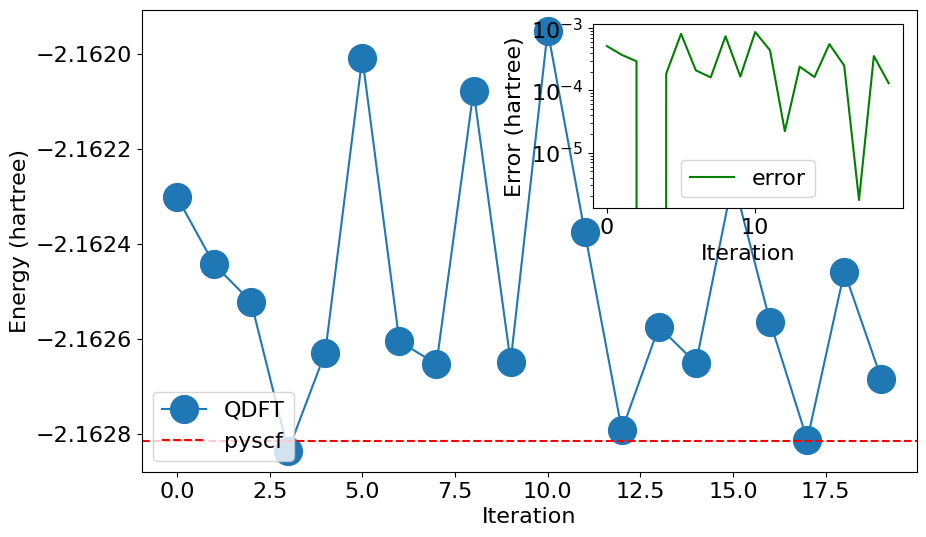

In [12]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(Energy_total, marker="o", ms=20, label="QDFT")
ax.axhline(y=mf.energy_tot(), ls="--", color="red", label="pyscf")
ax.set_ylabel('Energy (hartree)', fontsize=16)
ax.set_xlabel('Iteration', fontsize=16)
ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16, loc="lower left")
sub_ax = inset_axes(
    parent_axes=ax,
    width="40%",
    height="40%",
    borderpad=1  # padding between parent and inset axes
)
sub_ax.plot(Energy_total - mf.energy_tot(), color="green", label="error")
sub_ax.set_yscale('log')
sub_ax.set_ylabel('Error (hartree)', fontsize=16)
sub_ax.set_xlabel('Iteration', fontsize=16)
sub_ax.tick_params(axis='both', labelsize=16)
sub_ax.legend(fontsize=16)
plt.show()